In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv('../../datasets/Social_Network_Ads.csv')
df.drop(columns=['EstimatedSalary'], inplace=True)
df.head()

,Age,Purchased
0,19,0
1,35,0
2,26,0
3,27,0
4,19,0


In [3]:
df.isnull().sum()

Age          0
Purchased    0
dtype: int64

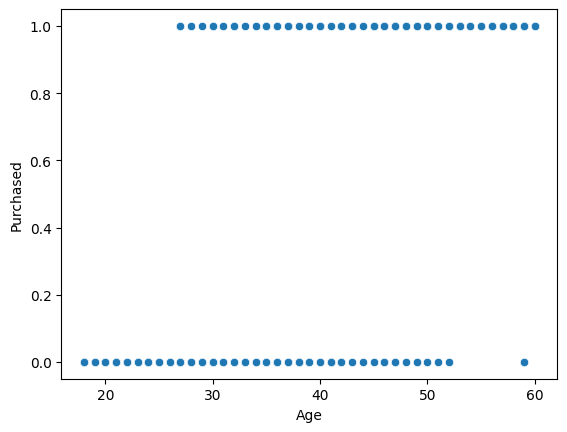

In [4]:
sns.scatterplot(x=df['Age'], y=df['Purchased'])
plt.show()

In [5]:
x = df[['Age']]
y = df['Purchased']

x.ndim, y.ndim

(2, 1)

In [6]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [7]:
lr = LogisticRegression()
lr.fit(x_train, y_train)

LogisticRegression()

In [8]:
lr.score(x_test, y_test)

0.9125

In [9]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, lr.predict(x_test))

array([[50,  2],
       [ 5, 23]], dtype=int64)

In [10]:
lr.predict(x_test)

array([1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0], dtype=int64)

In [11]:
# 19	0
lr.predict([[19]])

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0], dtype=int64)

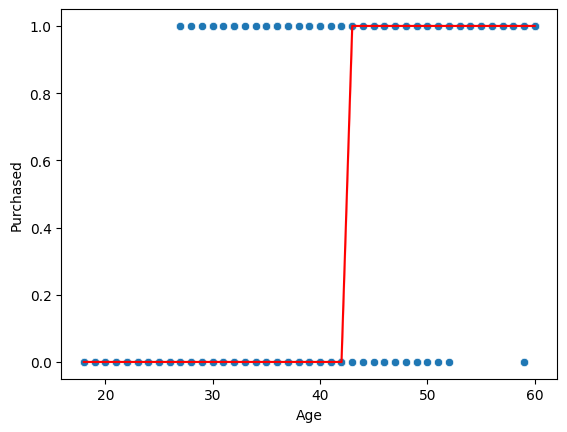

In [12]:
sns.scatterplot(x=df['Age'], y=df['Purchased'])
sns.lineplot(x=df['Age'], y=lr.predict(x), color='red')
plt.show()

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


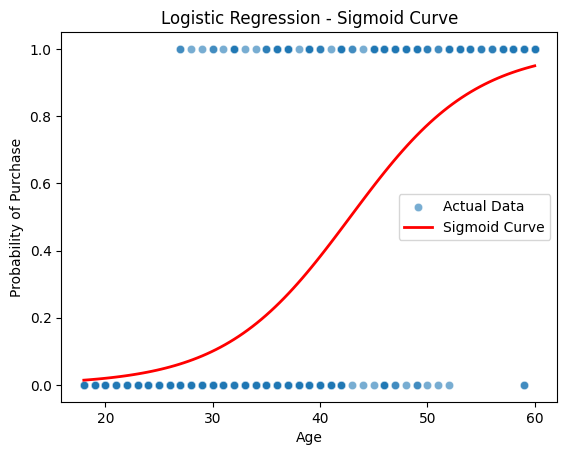

In [13]:
import numpy as np

# Generate age values in a range for smooth curve
age_range = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)

# Predict probabilities using logistic regression model
probabilities = lr.predict_proba(age_range)[:, 1]

# Plot actual data points
sns.scatterplot(x=df['Age'], y=df['Purchased'], label="Actual Data", alpha=0.6)

# Plot sigmoid curve
plt.plot(age_range, probabilities, color='red', linewidth=2, label="Sigmoid Curve")

# Labels and title
plt.xlabel("Age")
plt.ylabel("Probability of Purchase")
plt.title("Logistic Regression - Sigmoid Curve")
plt.legend()
plt.show()


---